# Практична робота 10. Неперервні розподіли в scipy.stats

**Виконав:** Maksym SHmelov  
**Група:** IT41  
**Варіант:** 2 — Львів

**Мета:** навчитися оцінювати параметри нормального розподілу за вибіркою та використовувати функції `.pdf()`, `.cdf()` і `.ppf()` з `scipy.stats.norm`.

У роботі використано навчальні дані з умови завдання. Липнева середньомісячна температура Львова дорівнює **18 °C**. На її основі буде згенеровано 30 умовних денних температур.

## Крок 1. Перевірка бібліотек і робочого середовища

In [1]:
import numpy as np
from scipy import stats
import scipy
import matplotlib
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)

NumPy: 2.3.5
SciPy: 1.17.0
Matplotlib: 3.10.8


## Приклад: наскрізна демонстрація на оцінках студентів

Спочатку розглянемо інший набір даних — результати контрольної роботи. За ним обчислимо середнє та стандартне відхилення, створимо нормальну модель і використаємо CDF та PPF. Це демонстраційний приклад, а власні завдання нижче виконуються на денних температурах Львова.

In [2]:
scores = np.array([
    62, 71, 75, 80, 68, 74, 90, 55, 77, 82,
    69, 73, 85, 60, 78, 72, 88, 65, 76, 81,
    70, 58, 83, 79, 67
])

scores_mean = scores.mean()
scores_std = scores.std()
scores_dist = stats.norm(loc=scores_mean, scale=scores_std)

p_70_85 = scores_dist.cdf(85) - scores_dist.cdf(70)
top10_cutoff = scores_dist.ppf(0.90)

print("Середнє:", round(scores_mean, 2))
print("Стандартне відхилення:", round(scores_std, 2))
print("P(70 <= X <= 85):", round(p_70_85, 3))
print("90-й процентиль:", round(top10_cutoff, 2))

Середнє: 73.52
Стандартне відхилення: 9.01
P(70 <= X <= 85): 0.551
90-й процентиль: 85.07


## Вибір власного варіанта

Для практичної роботи обрано **варіант 2 — Львів**. Місячні середні температури взято з таблиці завдання 1. Липневе значення (сьомий елемент масиву) використовується як центр генерації денних температур.

In [3]:
VARIANT = 2
CITY = "Львів"

monthly_temps = np.array([-3, -2, 2, 8, 13, 16, 18, 17, 13, 8, 3, -1])
months = np.array(["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
                   "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"])

july_mean = monthly_temps[6]

print("Варіант:", VARIANT)
print("Місто:", CITY)
print("Липнева середньомісячна температура:", july_mean, "°C")

Варіант: 2
Місто: Львів
Липнева середньомісячна температура: 18 °C


## Завдання 1. Побудова вибірки денних температур

За умовою використовуємо липневе середнє як центр нормального випадкового розподілу, стандартне відхилення генерації 2.5 °C і 30 спостережень. Фіксація seed забезпечує відтворюваність: повторний запуск дає ту саму вибірку.

In [4]:
np.random.seed(VARIANT)
daily_temps = np.random.normal(loc=july_mean, scale=2.5, size=30)

print("Вибірка денних температур (°C):")
print(np.round(daily_temps, 2))
print("Середнє вибірки:", round(daily_temps.mean(), 4), "°C")
print("Стандартне відхилення вибірки:", round(daily_temps.std(), 4), "°C")
print("Липневе середнє з таблиці:", july_mean, "°C")

Вибірка денних температур (°C):
[16.96 17.86 12.66 22.1  13.52 15.9  19.26 14.89 15.36 15.73 19.38 23.73
 18.1  15.21 19.35 16.51 17.95 20.94 16.13 18.02 15.8  17.61 18.64 15.53
 17.15 17.41 16.41 15.03 14.45 17.62]
Середнє вибірки: 17.1727 °C
Стандартне відхилення вибірки: 2.3755 °C
Липневе середнє з таблиці: 18 °C


## Завдання 2. Параметри нормального розподілу

Параметр `mean` (μ) — середнє значення вибірки, а `std` (σ) — її стандартне відхилення. Створюємо теоретичний нормальний розподіл з цими параметрами через `stats.norm(loc=mean, scale=std)`.

In [5]:
mean = daily_temps.mean()
std = daily_temps.std()
dist = stats.norm(loc=mean, scale=std)

print(f"μ (mean) = {mean:.4f} °C")
print(f"σ (std)  = {std:.4f} °C")
print("Підібрана модель: Normal(μ, σ) для денної температури Львова")

μ (mean) = 17.1727 °C
σ (std)  = 2.3755 °C
Підібрана модель: Normal(μ, σ) для денної температури Львова


## Завдання 3. Гістограма і теоретична PDF-крива

Гістограма будується з параметром `density=True`, тому її висота відображає густину, а не абсолютну кількість спостережень. На той самий графік накладається теоретична крива щільності `dist.pdf(x)`.

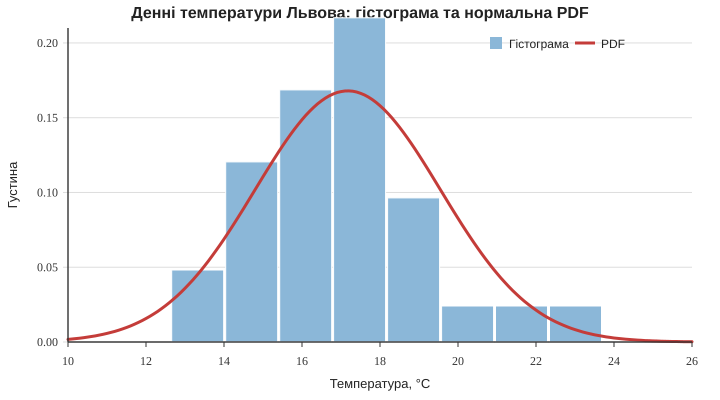

Графік побудовано: гістограма має density=True, поверх неї накладено dist.pdf(x).


In [6]:
x = np.linspace(daily_temps.min() - 2, daily_temps.max() + 2, 300)

plt.figure(figsize=(9, 5))
plt.hist(daily_temps, bins=8, density=True, edgecolor="white",
         alpha=0.75, label="Гістограма денних температур")
plt.plot(x, dist.pdf(x), linewidth=2.5, label="Теоретична PDF-крива")
plt.title("Денні температури Львова: гістограма та нормальна модель")
plt.xlabel("Температура, °C")
plt.ylabel("Густина ймовірності")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Графік побудовано: гістограма має density=True, поверх неї накладено dist.pdf(x).")

**Оцінка графіка:** PDF-крива проходить поблизу основної маси стовпців і показує загальну дзвоноподібну форму розподілу. Водночас окремі стовпці помітно відхиляються від кривої. Це очікувано, оскільки вибірка містить лише 30 випадкових значень: випадкові коливання частот у бінів не зобов'язані точно повторювати теоретичну криву.

## Завдання 4. Ймовірність потрапляння в діапазон

За допомогою CDF обчислимо ймовірність того, що значення нормальної моделі потрапить у межі одного стандартного відхилення від середнього: від `mean - std` до `mean + std`. Різниця двох значень CDF дає ймовірність інтервалу.

In [7]:
lower = mean - std
upper = mean + std
prob_one_std = dist.cdf(upper) - dist.cdf(lower)

# Емпірична частка спостережень із нашої конкретної вибірки в цьому інтервалі
empirical_share = np.mean((daily_temps >= lower) & (daily_temps <= upper))

print(f"Інтервал: [{lower:.4f}; {upper:.4f}] °C")
print(f"Теоретична ймовірність за CDF: {prob_one_std:.6f} ({prob_one_std * 100:.2f}%)")
print(f"Емпірична частка у вибірці: {empirical_share:.4f} ({empirical_share * 100:.1f}%)")
print("Кількість значень у межах інтервалу:",
      np.sum((daily_temps >= lower) & (daily_temps <= upper)), "із", len(daily_temps))

Інтервал: [14.7972; 19.5481] °C
Теоретична ймовірність за CDF: 0.682689 (68.27%)
Емпірична частка у вибірці: 0.8000 (80.0%)
Кількість значень у межах інтервалу: 24 із 30


**Порівняння з правилом 68–95–99.7:** для нормального розподілу в межах одного стандартного відхилення від середнього міститься приблизно 68.27% значень. Отримане теоретичне значення 68.27% точно відповідає цьому правилу. У конкретній вибірці всередині інтервалу опинилися 24 із 30 значень, тобто 80%. Це не суперечність: правило описує теоретичну модель, а невелика випадкова вибірка може мати іншу частку через випадкові коливання.

## Завдання 5. Квантиль через PPF

95-й процентиль — це таке значення температури, нижче якого за підібраною нормальною моделлю знаходиться 95% розподілу. Знайдемо його за допомогою `dist.ppf(0.95)`.

In [8]:
percentile_95 = dist.ppf(0.95)

print(f"95-й процентиль: {percentile_95:.4f} °C")
print(f"Перевірка через CDF: {dist.cdf(percentile_95):.4f}")

95-й процентиль: 21.0800 °C
Перевірка через CDF: 0.9500


**Пояснення:** 95-й процентиль дорівнює приблизно **21.08 °C**. Це означає, що згідно з підібраною нормальною моделлю приблизно 95% денних температур будуть не вищими за 21.08 °C, а близько 5% — вищими. Функція `.cdf(x)` приймає значення температури й повертає накопичену ймовірність, а `.ppf(q)` приймає накопичену ймовірність і повертає відповідне їй значення температури.

## Письмові відповіді на контрольні питання

**1. Чим відрізняються `.pdf(x)` і `.cdf(x)`?**

`.pdf(x)` повертає значення щільності ймовірності в точці x. Воно показує висоту теоретичної кривої в цій точці, але не є ймовірністю отримати рівно це значення. `.cdf(x)` повертає накопичену ймовірність (P(X \leq x)), тобто ймовірність того, що випадкова величина не перевищить x. Для неперервного розподілу ймовірність інтервалу обчислюють площею під PDF-кривою або різницею двох значень CDF.

**2. Чому `.pdf(x)` може бути більшим за 1?**

PDF — це щільність, а не сама ймовірність. Її значення вимірюється у зворотних одиницях вимірювання величини. Для вузького розподілу крива може бути високою, тому в окремій точці щільність може перевищувати 1. Важливо, що ймовірність задається площею під кривою на інтервалі, а повна площа під PDF на всій числовій осі дорівнює 1. Тому значення щільності вище 1 не порушує правила про ймовірність від 0 до 1.

**3. Чому `.ppf()` називають оберненою до `.cdf()` функцією?**

`.cdf(x)` отримує значення x і повертає накопичену ймовірність q. `.ppf(q)` робить навпаки: отримує ймовірність q від 0 до 1 і повертає таке значення x, для якого CDF дорівнює q. Наприклад, `dist.ppf(0.95)` знаходить 95-й процентиль, а `dist.cdf(dist.ppf(0.95))` повертає приблизно 0.95.

## Висновок

Під час практичної роботи було згенеровано відтворювану вибірку з 30 денних температур Львова на основі липневого середнього 18 °C. За вибіркою оцінено параметри нормального розподілу: середнє μ = 17.1727 °C і стандартне відхилення σ = 2.3755 °C. Побудовано гістограму з нормуванням густини та накладено PDF-криву. За допомогою CDF розраховано ймовірність потрапляння в інтервал одного стандартного відхилення, а через PPF знайдено 95-й процентиль. Також розглянуто значення функцій PDF, CDF і PPF та їх взаємозв'язок.